# Structural Preprocessing

**NX-421 — Neural Signals and Signal Processing**

In this notebook, we preprocess the T1-weighted anatomical MRI from the Human Connectome Project (HCP) language-task dataset.

Structural preprocessing consists of three steps:

1. **Skull stripping:** Extract the brain by removing the skull and surrounding non-brain tissues.
2. **Tissue segmentation:** Separate the brain into gray matter (GM), white matter (WM), and cerebrospinal fluid (CSF).
3. **MNI registration:** Align the anatomical image with the MNI152 standard template.

We use FSL, as introduced in the laboratory sessions, and inspect the results after each step to check that the preprocessing worked correctly.

## 0. Setup and input data

We first import the libraries needed for image manipulation, visualization, and preprocessing.

NiBabel is used to read NIfTI images and inspect their spatial information. NumPy is used for array operations, while Matplotlib allows us to visualize the anatomical images and the preprocessing results.

For skull stripping and segmentation, we use FSL's BET and FAST tools, respectively.

The original MRI is kept unchanged, and the processed files are saved in separate subdirectories under `outputs`: `structural` for skull stripping and tissue segmentation, and `registration_mni` for MNI registration.

In [1]:
# General imports
import os
from pathlib import Path
import subprocess
import shutil

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

# Load FSL in Neurodesk, as in Lab 2
import module as lmod

await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')

# Project directories
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "structural"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Check FSL installation
print("Project directory:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

print("\nFSL tools:")

for tool in ["bet", "fast", "fslmaths"]:
    tool_path = shutil.which(tool)
    print(f"{tool}: {tool_path}")

    if tool_path is None:
        raise RuntimeError(f"{tool} is not available.")

# Check availability of FSLeyes
print("\nFSLeyes:", shutil.which("fsleyes"))

Project directory: /data/Desktop/myfiles/NX421-MiniProject-1
Data directory: /data/Desktop/myfiles/NX421-MiniProject-1/data
Output directory: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/structural

FSL tools:
bet: /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/bet
fast: /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fast
fslmaths: /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fslmaths

FSLeyes: /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsleyes


### 0.1 Loading the anatomical image

The dataset contains a T1-weighted structural MRI stored in NIfTI format (`.nii.gz`).

Before applying any preprocessing, we check the image dimensions, voxel resolution, and orientation.

This initial inspection is important because the anatomical image will be used for both brain extraction and tissue segmentation.

In [2]:
# Path to the HCP T1-weighted anatomical image
anatomical_path = DATA_DIR / "T1" / "T1w.nii.gz"

if not anatomical_path.is_file():
    raise FileNotFoundError(
        f"Anatomical MRI not found: {anatomical_path}"
    )

# Load the anatomical MRI
t1_img = nib.load(str(anatomical_path))
t1_data = t1_img.get_fdata(dtype=np.float32)

# Verify image dimensions
if t1_data.ndim != 3:
    raise ValueError("Expected a 3D anatomical MRI.")

# Display image information
print("Anatomical image:", anatomical_path)
print("Image dimensions:", t1_img.shape)
print("Voxel size (mm):", t1_img.header.get_zooms()[:3])
print("Orientation:", nib.aff2axcodes(t1_img.affine))
print("Intensity range:", t1_data.min(), t1_data.max())

Anatomical image: /data/Desktop/myfiles/NX421-MiniProject-1/data/T1/T1w.nii.gz
Image dimensions: (260, 311, 260)
Voxel size (mm): (np.float32(0.7), np.float32(0.7), np.float32(0.7))
Orientation: ('L', 'A', 'S')
Intensity range: 0.0 3407.6182


### 0.2 Initial inspection of the anatomical MRI

The T1-weighted image has dimensions of 260 × 311 × 260 voxels, with an isotropic voxel resolution of 0.7 mm.

This high spatial resolution allows us to distinguish anatomical structures and tissue boundaries in detail, which is useful for the following skull stripping and segmentation steps.

The image is oriented along the Left-Anterior-Superior (LAS) axes. Before preprocessing, we visualize the anatomical image in the three orthogonal planes to inspect the brain and surrounding tissues.

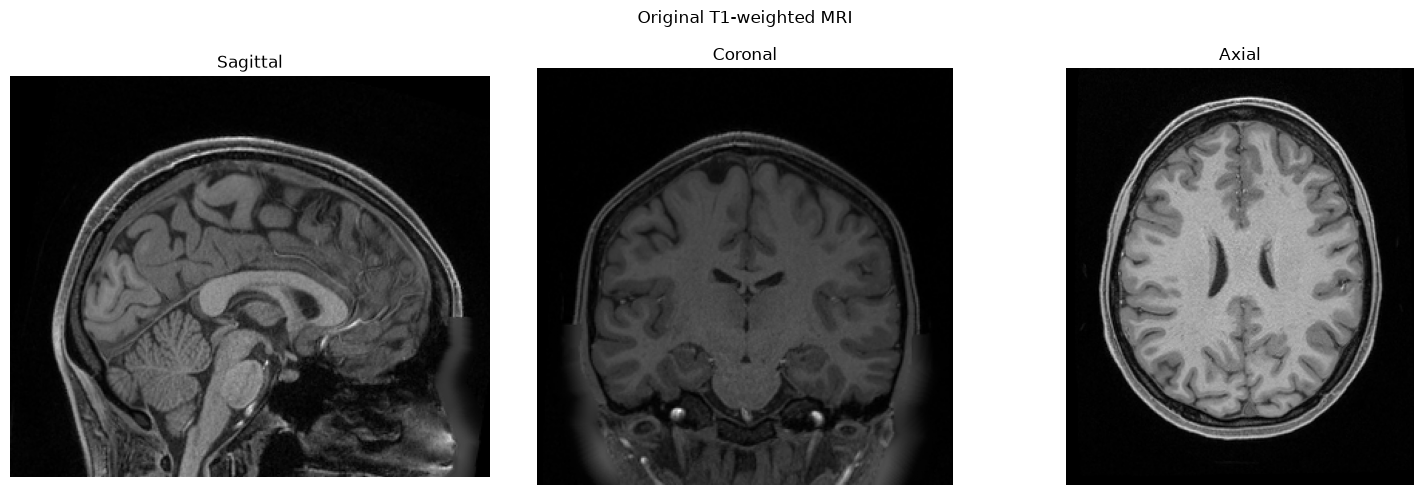

In [3]:
# Reorient the image for consistent visualization
t1_display = nib.as_closest_canonical(t1_img).get_fdata()

# Select the central slice along each axis
x = t1_display.shape[0] // 2
y = t1_display.shape[1] // 2
z = t1_display.shape[2] // 2

# Display the three anatomical planes
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(np.rot90(t1_display[x, :, :]), cmap="gray")
axes[0].set_title("Sagittal")

axes[1].imshow(np.rot90(t1_display[:, y, :]), cmap="gray")
axes[1].set_title("Coronal")

axes[2].imshow(np.rot90(t1_display[:, :, z]), cmap="gray")
axes[2].set_title("Axial")

for ax in axes:
    ax.axis("off")

plt.suptitle("Original T1-weighted MRI")
plt.tight_layout()
plt.show()

### 0.3 Interactive Visualization with FSLeyes

As in the laboratory sessions, we also use FSLeyes to inspect the anatomical MRI interactively.

Unlike the Matplotlib figures, which show selected slices, FSLeyes allows us to navigate through the complete 3D volume and examine anatomical structures in different planes.

We first load the original T1-weighted image to inspect the brain and surrounding tissues before preprocessing.

In [4]:
# Open FSLeyes with the original anatomical MRI
# --cliserver allows us to reuse the same window
fsleyes_process = subprocess.Popen([
    "fsleyes",
    "--cliserver",
    str(anatomical_path)
])

print("Original T1w loaded in FSLeyes.")

Original T1w loaded in FSLeyes.


(fsleyes:25794): dbind-WARNING **: 15:19:06.306: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/1651318849/at-spi/bus_100: No such file or directory


## 1. Skull Stripping

The first preprocessing step is skull stripping, which removes the skull and other non-brain tissues from the anatomical MRI while preserving the brain.

We use FSL's Brain Extraction Tool (BET), as introduced in Lab 2. BET estimates the brain boundary and generates a skull-stripped image together with a binary brain mask.

We enable robust brain centre estimation (`-R`) and use the default fractional intensity threshold (`-f 0.5`). The mask will then be inspected to check whether the brain has been correctly extracted.

This step is important because the following tissue segmentation will be performed on the skull-stripped image.

In [5]:
# Output paths for skull stripping
brain_path = OUTPUT_DIR / "T1w_brain.nii.gz"
mask_path = OUTPUT_DIR / "T1w_brain_mask.nii.gz"

# Skull stripping using FSL BET
subprocess.run([
    "bet",
    str(anatomical_path),
    str(brain_path),
    "-R",
    "-m",
    "-f", "0.5"
], check=True)

# Check that the output files were created
assert brain_path.exists(), "Brain-extracted image not found."
assert mask_path.exists(), "Brain mask not found."

print("Skull stripping completed.")
print("Extracted brain:", brain_path)
print("Brain mask:", mask_path)

Skull stripping completed.
Extracted brain: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/structural/T1w_brain.nii.gz
Brain mask: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/structural/T1w_brain_mask.nii.gz


### 1.1 Quality Control of Skull Stripping

After applying BET, we compare the original T1-weighted image with the skull-stripped image and its corresponding brain mask.

The goal is to verify that the skull and surrounding tissues have been removed without excluding important brain regions.

We inspect the sagittal, coronal, and axial views, paying particular attention to the frontal cortex, superior regions, cerebellum, and brainstem.

The brain mask is overlaid on the original anatomical image to assess how well the extraction follows the brain boundaries.

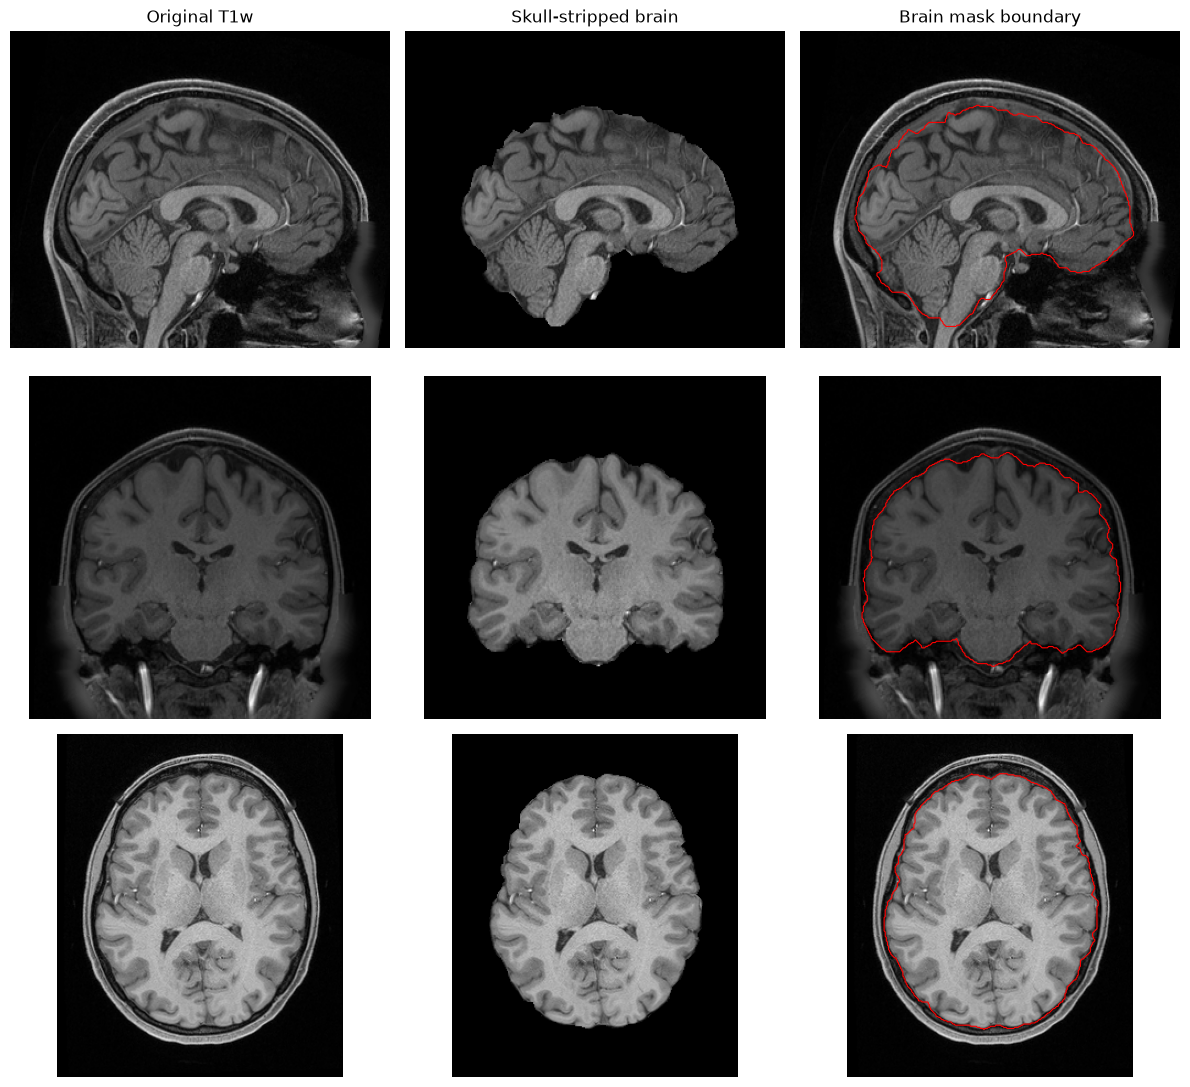

In [6]:
# Load the skull-stripped image and brain mask
brain_img = nib.load(str(brain_path))
mask_img = nib.load(str(mask_path))

# Check that the images are in the same space
assert brain_img.shape == t1_img.shape
assert mask_img.shape == t1_img.shape
assert np.allclose(brain_img.affine, t1_img.affine)
assert np.allclose(mask_img.affine, t1_img.affine)

# Reorient for visualization
brain_display = nib.as_closest_canonical(brain_img).get_fdata()
mask_display = nib.as_closest_canonical(mask_img).get_fdata()

# Find the approximate centre of the extracted brain
brain_center = np.rint(
    np.argwhere(mask_display > 0).mean(axis=0)
).astype(int)

fig, axes = plt.subplots(3, 3, figsize=(12, 11))

plane_names = ["Sagittal", "Coronal", "Axial"]

for axis in range(3):
    slice_index = int(brain_center[axis])

    original_slice = np.rot90(
        np.take(t1_display, slice_index, axis=axis)
    )
    brain_slice = np.rot90(
        np.take(brain_display, slice_index, axis=axis)
    )
    mask_slice = np.rot90(
        np.take(mask_display, slice_index, axis=axis)
    )

    axes[axis, 0].imshow(original_slice, cmap="gray")
    axes[axis, 1].imshow(brain_slice, cmap="gray")

    axes[axis, 2].imshow(original_slice, cmap="gray")
    axes[axis, 2].contour(
        mask_slice,
        levels=[0.5],
        colors="red",
        linewidths=0.8
    )

    for ax in axes[axis]:
        ax.axis("off")

    axes[axis, 0].set_ylabel(plane_names[axis])

axes[0, 0].set_title("Original T1w")
axes[0, 1].set_title("Skull-stripped brain")
axes[0, 2].set_title("Brain mask boundary")

plt.tight_layout()
plt.show()

### 1.2 Skull Stripping Results

The skull-stripped image was compared with the original T1-weighted MRI in sagittal, coronal, and axial views.

Overall, BET with robust centre estimation (`-R -f 0.5`) removed the skull and scalp while preserving the cerebral cortex, cerebellum, and brainstem. In the coronal and axial views, the mask follows the brain boundary closely.

The extraction is not perfect, however. In the midsagittal view, some non-brain tissue remains inside the mask: the superior sagittal sinus/dura along the top of the midline (visible as a jagged upper edge) and a bright structure near the base of the brainstem. These residual voxels are small and located outside the cortical regions relevant to our language-task analysis, so we did not apply manual corrections and kept the BET output for tissue segmentation.

### 1.3 Interactive Quality Control with FSLeyes

We use FSLeyes to inspect the brain extraction in more detail, following the quality-control approach used in Lab 2.

The original anatomical image is displayed together with the binary brain mask. We navigate through the different slices and check whether the mask follows the brain boundaries.

Particular attention is given to the frontal cortex, superior regions, cerebellum, and brainstem, where incorrect extraction could affect subsequent analyses.

In [7]:
# Add the brain mask to the existing FSLeyes window
subprocess.run([
    "fsleyes",
    "--cliserver",
    str(mask_path)
], check=True)

print("Brain mask added to FSLeyes.")

Brain mask added to FSLeyes.


## 2. Brain Tissue Segmentation

After skull stripping, we segment the brain into three main tissue classes: gray matter (GM), white matter (WM), and cerebrospinal fluid (CSF).

We use FSL FAST (FMRIB's Automated Segmentation Tool), as introduced in Lab 2. FAST uses differences in MRI intensities and spatial information to classify brain tissues.

In T1-weighted images, white matter generally appears brighter than gray matter, while CSF is darker.

FAST is applied to the skull-stripped image, since non-brain tissues could interfere with the segmentation. We request three tissue classes and inspect the resulting partial volume estimation (PVE) maps.

These maps represent the estimated proportion of each tissue within a voxel, rather than simply assigning a binary tissue label.

In [8]:
# Output prefix for tissue segmentation
segmentation_prefix = OUTPUT_DIR / "T1w_fast"

# Run FAST on the skull-stripped T1 image
subprocess.run([
    "fast",
    "-t", "1",
    "-n", "3",
    "-o", str(segmentation_prefix),
    str(brain_path)
], check=True)

# Paths to the partial volume estimation maps
csf_path = OUTPUT_DIR / "T1w_fast_pve_0.nii.gz"
gm_path = OUTPUT_DIR / "T1w_fast_pve_1.nii.gz"
wm_path = OUTPUT_DIR / "T1w_fast_pve_2.nii.gz"

# Verify that all three maps were created
for tissue, path in [
    ("CSF", csf_path),
    ("Gray matter", gm_path),
    ("White matter", wm_path)
]:
    assert path.exists(), f"Missing output: {path}"
    print(f"{tissue}: {path.name}")

print("\nTissue segmentation completed.")

CSF: T1w_fast_pve_0.nii.gz
Gray matter: T1w_fast_pve_1.nii.gz
White matter: T1w_fast_pve_2.nii.gz

Tissue segmentation completed.


### 2.1 Interactive Visualization of Segmented Tissues

FAST generates three partial-volume estimation (PVE) maps corresponding to CSF, gray matter, and white matter.

Following Lab 2, we load these three maps in FSLeyes and overlay them on the skull-stripped anatomical image.

We use different colours to distinguish the tissues:

- CSF: Red
- Gray matter: Green
- White matter: Blue

We inspect the resulting maps to check whether the tissue classification agrees with the anatomical structures visible in the T1-weighted image.

In [10]:
# Add the skull-stripped brain and segmented tissues
# to the same FSLeyes window
subprocess.run([
    "fsleyes",
    "--cliserver",
    str(brain_path),
    str(csf_path),
    str(gm_path),
    str(wm_path)
], check=True)

print("Segmented tissues added to FSLeyes.")

Segmented tissues added to FSLeyes.


### 2.2 Visualization of Segmented Tissues

To complement the interactive inspection in FSLeyes, we also display the three tissue maps using Matplotlib.

Each partial-volume map is overlaid on the skull-stripped T1-weighted image, using red for CSF, green for gray matter, and blue for white matter.

This allows us to compare the spatial distribution of the tissues in the same anatomical slice and provides a figure for reporting the segmentation results.

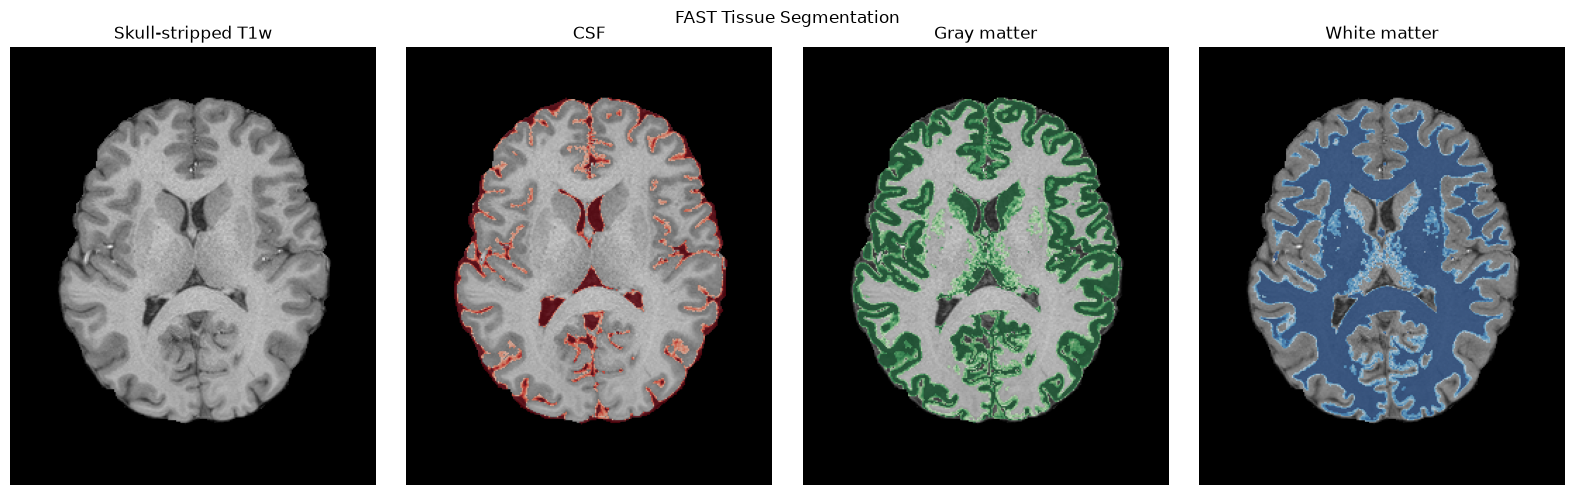

In [11]:
# Load FAST partial-volume maps
csf_img = nib.load(str(csf_path))
gm_img = nib.load(str(gm_path))
wm_img = nib.load(str(wm_path))

# Verify image geometry
for tissue_img in [csf_img, gm_img, wm_img]:
    assert tissue_img.shape == brain_img.shape
    assert np.allclose(tissue_img.affine, brain_img.affine)

# Reorient images consistently for visualization
csf_display = nib.as_closest_canonical(csf_img).get_fdata()
gm_display = nib.as_closest_canonical(gm_img).get_fdata()
wm_display = nib.as_closest_canonical(wm_img).get_fdata()

# Select an axial slice through the brain
z = int(brain_center[2])
background = np.rot90(brain_display[:, :, z])

tissues = [
    (csf_display, "CSF", "Reds"),
    (gm_display, "Gray matter", "Greens"),
    (wm_display, "White matter", "Blues")
]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(background, cmap="gray")
axes[0].set_title("Skull-stripped T1w")

for ax, (data, title, cmap) in zip(axes[1:], tissues):
    tissue_slice = np.rot90(data[:, :, z])

    ax.imshow(background, cmap="gray")
    ax.imshow(
        np.ma.masked_less(tissue_slice, 0.2),
        cmap=cmap,
        vmin=0,
        vmax=1,
        alpha=0.7
    )

    ax.set_title(title)

for ax in axes:
    ax.axis("off")

plt.suptitle("FAST Tissue Segmentation")
plt.tight_layout()
plt.show()

### 2.3 Tissue Segmentation Results

The three partial-volume maps generated by FAST were visualized on the skull-stripped T1-weighted image.

In the inspected slices, the segmentation appears anatomically reasonable. CSF is mainly identified in the ventricles and cortical sulci, gray matter follows the cortical ribbon, and white matter is concentrated beneath the cortex and in the internal regions of the brain.

One limitation is visible in the deep gray-matter nuclei (thalamus, putamen, caudate): these voxels receive mixed gray- and white-matter fractions. This is a known limitation of intensity-based segmentation such as FAST, because these nuclei have T1 intensities intermediate between cortical gray matter and white matter. Partial-volume effects are also visible at tissue boundaries.

Overall, the segmentation is satisfactory for the cortical tissues, which are the most relevant for our analysis, although visual inspection does not guarantee accurate classification throughout the entire brain.

### 2.4 Quantitative Quality Control

In addition to visual inspection, we check the range of the partial-volume estimates and calculate approximate tissue volumes.

Each tissue fraction should lie between 0 and 1. Within the extracted brain, the fractions of CSF, GM, and WM should approximately sum to 1.

The tissue volumes are estimated by summing the partial-volume fractions and multiplying by the physical volume of one voxel.

In [12]:
# Tissue maps as NumPy arrays
tissue_maps = {
    "CSF": csf_img.get_fdata(dtype=np.float32),
    "Gray matter": gm_img.get_fdata(dtype=np.float32),
    "White matter": wm_img.get_fdata(dtype=np.float32)
}

# Volume of a single voxel in mm³
voxel_volume = np.prod(t1_img.header.get_zooms()[:3])

print("FAST segmentation summary")
print("-" * 45)

for tissue, data in tissue_maps.items():

    if not np.isfinite(data).all():
        raise ValueError(f"Invalid values found in {tissue} map.")

    if data.min() < -1e-4 or data.max() > 1.0001:
        raise ValueError(f"Unexpected PVE values in {tissue} map.")

    # Estimated tissue volume from partial-volume fractions
    volume_ml = np.sum(data) * voxel_volume / 1000

    print(f"{tissue}:")
    print(f"  PVE range: {data.min():.3f} - {data.max():.3f}")
    print(f"  Estimated volume: {volume_ml:.1f} mL")

# Check whether tissue fractions approximately sum to 1 inside the brain
brain_mask = mask_img.get_fdata() > 0

pve_sum = sum(tissue_maps.values())

print("\nMean tissue fraction sum inside brain:",
      np.mean(pve_sum[brain_mask]))

FAST segmentation summary
---------------------------------------------
CSF:
  PVE range: 0.000 - 1.000
  Estimated volume: 203.7 mL
Gray matter:
  PVE range: 0.000 - 1.000
  Estimated volume: 627.4 mL
White matter:
  PVE range: 0.000 - 1.000
  Estimated volume: 490.5 mL

Mean tissue fraction sum inside brain: 1.0


### 2.5 Quantitative Results

The estimated tissue volumes were 203.7 mL for CSF, 627.4 mL for gray matter, and 490.5 mL for white matter.

All three PVE maps contained values between 0 and 1, as expected. The mean sum of tissue fractions inside the brain mask was 1.0, which is consistent with FAST's three-class partial-volume estimation.

The estimated tissue volumes appear plausible, and the results are consistent with the anatomical patterns observed during visual inspection. However, these checks do not provide an independent measure of segmentation accuracy, particularly at tissue boundaries.

## 3. Registration to MNI Space

After skull stripping and tissue segmentation, the next step is to register the subject's anatomical MRI to the MNI152 standard template.

The purpose of registration is to align individual brain images to a common reference space, making it easier to compare anatomical locations across subjects and relate our results to standard brain atlases.

Following Lab 2, we use FSL FLIRT (FMRIB's Linear Image Registration Tool) to perform affine registration. This requires two images:

- **Moving image:** The skull-stripped T1-weighted MRI obtained using BET.
- **Reference image:** The MNI152 T1-weighted brain template at 1 mm resolution.

We use a 12-degree-of-freedom affine transformation, which allows translation, rotation, scaling, and shearing. Since both images are T1-weighted, we use normalized correlation as the registration cost function.

We first inspect the initial alignment between the subject and the template. After registration, we compare the resulting image with the MNI template to assess whether the anatomical structures are better aligned.

The registration produces a transformed T1-weighted image in MNI space and the corresponding affine transformation matrix.

In [13]:
# Input image: skull-stripped T1w from BET
source = brain_path

# Reference image: MNI152 brain template (1 mm)
reference = Path(os.environ["FSLDIR"]) / "data" / "standard" / "MNI152_T1_1mm_brain.nii.gz"

# Directory for registration outputs
REGISTRATION_DIR = PROJECT_ROOT / "outputs" / "registration_mni"
REGISTRATION_DIR.mkdir(parents=True, exist_ok=True)

# Output paths
registered_path = REGISTRATION_DIR / "T1w_brain_MNI.nii.gz"
matrix_path = REGISTRATION_DIR / "T1w_to_MNI_affine.mat"

# Verify inputs
if not source.is_file():
    raise FileNotFoundError(f"Source image not found: {source}")

if not reference.is_file():
    raise FileNotFoundError(f"MNI template not found: {reference}")

# Inspect the source and reference
source_img = nib.load(str(source))
reference_img = nib.load(str(reference))

print("Moving image:", source.name)
print("Moving image dimensions:", source_img.shape)
print("Moving image voxel size:", source_img.header.get_zooms()[:3])

print("\nReference image:", reference.name)
print("Reference dimensions:", reference_img.shape)
print("Reference voxel size:", reference_img.header.get_zooms()[:3])

print("\nRegistration output directory:", REGISTRATION_DIR)

Moving image: T1w_brain.nii.gz
Moving image dimensions: (260, 311, 260)
Moving image voxel size: (np.float32(0.7), np.float32(0.7), np.float32(0.7))

Reference image: MNI152_T1_1mm_brain.nii.gz
Reference dimensions: (182, 218, 182)
Reference voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))

Registration output directory: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/registration_mni


### 3.1 Initial Alignment with the MNI Template

Before registration, we inspect the subject's skull-stripped T1-weighted image and the MNI152 brain template.

The two images have different voxel resolutions: 0.7 mm for the subject and 1 mm for the MNI template. They may also differ in orientation, position, and overall brain shape.

We visualize the images together to assess their initial alignment. At this stage, no spatial transformation has been applied, so we do not expect the anatomical structures to match perfectly.

This comparison will serve as a reference for evaluating the improvement obtained with FLIRT.

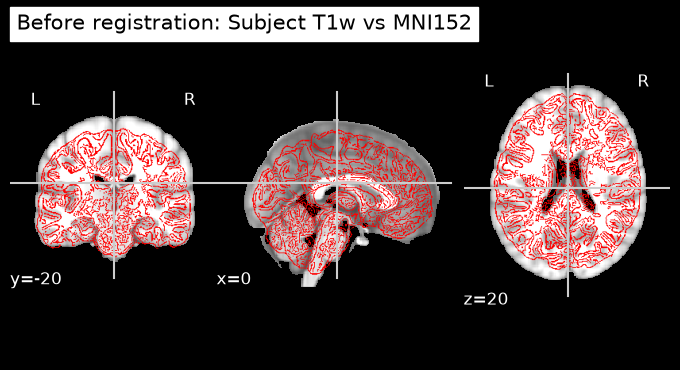

In [14]:
from nilearn import plotting

# Compare subject brain boundaries with the MNI template
before = plotting.plot_anat(
    str(reference),
    title="Before registration: Subject T1w vs MNI152",
    display_mode="ortho",
    cut_coords=(0, -20, 20),
    dim=-0.3
)

# Overlay anatomical edges of the subject T1w
before.add_edges(str(source), color="red")

plotting.show()

### 3.2 Linear Registration Using FSL FLIRT

We now register the subject's skull-stripped T1-weighted image to the MNI152 template using FSL FLIRT, following Lab 2.

We use a 12-degree-of-freedom affine transformation, allowing translation, rotation, scaling, and shearing. The registration cost function is normalized correlation (`normcorr`), which is suitable for aligning images with the same T1-weighted contrast.

The subject's anatomical image is the moving image, while the MNI152 template remains fixed. Trilinear interpolation is used to resample the registered image onto the reference grid.

We save both the registered anatomical image and the affine transformation matrix for later use.

In [15]:
# Register the skull-stripped T1w image to MNI152 space
subprocess.run([
    "flirt",
    "-in", str(source),
    "-ref", str(reference),
    "-out", str(registered_path),
    "-omat", str(matrix_path),
    "-dof", "12",
    "-cost", "normcorr",
    "-interp", "trilinear"
], check=True)

# Verify that registration outputs exist
if not registered_path.is_file():
    raise FileNotFoundError("Registered T1w image was not created.")

if not matrix_path.is_file():
    raise FileNotFoundError("Affine transformation matrix was not created.")

print("FLIRT registration completed.")
print("Registered image:", registered_path)
print("Transformation matrix:", matrix_path)

FLIRT registration completed.
Registered image: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/registration_mni/T1w_brain_MNI.nii.gz
Transformation matrix: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/registration_mni/T1w_to_MNI_affine.mat


### 3.3 Quality Control of MNI Registration

After applying FLIRT, we compare the registered T1-weighted image with the MNI152 template to evaluate the alignment.

As in the initial comparison, the MNI template is displayed in grayscale, while the anatomical edges of the subject's registered image are overlaid in red.

We use the same cut coordinates as before registration, allowing us to compare the anatomical alignment before and after applying FLIRT.

We focus on the overall brain shape, cortical boundaries, midline structures, and ventricles. A good registration should reduce visible differences between the subject and the reference, although individual anatomical variations will remain.

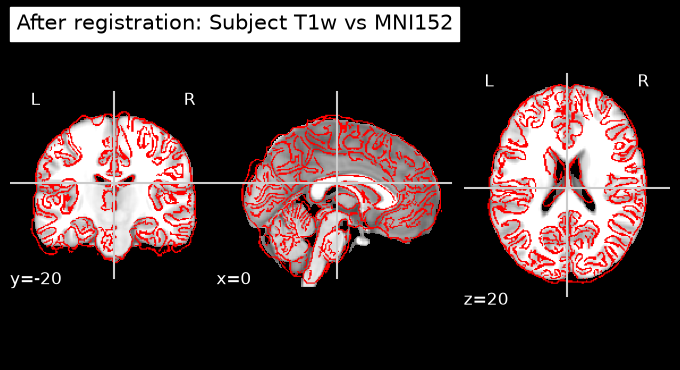

In [16]:
# Compare registered T1w boundaries with the MNI template
after = plotting.plot_anat(
    str(reference),
    title="After registration: Subject T1w vs MNI152",
    display_mode="ortho",
    cut_coords=(0, -20, 20),
    dim=-0.3
)

# Overlay edges of the registered anatomical image
after.add_edges(str(registered_path), color="red")

plotting.show()

### 3.4 Registration Results

The registered T1-weighted image was compared with the MNI152 template using the same anatomical views as before registration.

After applying FLIRT, the subject's brain appears better aligned with the template. The outer brain boundaries match more closely, and the alignment of internal structures, including the midline and ventricles, has improved.

Some differences remain, particularly around cortical folds, which is expected because affine registration adjusts the global position and shape of the brain without accounting for all individual anatomical variations.

Overall, the registration appears satisfactory based on the inspected slices. Further checks of the transformation matrix and output image geometry are performed below.

In [17]:
# Load the registered image and affine matrix
registered_img = nib.load(str(registered_path))
affine_matrix = np.loadtxt(matrix_path)

# Check registered image geometry
assert registered_img.shape == reference_img.shape
assert np.allclose(registered_img.affine, reference_img.affine)

# Check affine transformation matrix
assert affine_matrix.shape == (4, 4)
assert np.all(np.isfinite(affine_matrix))
assert np.allclose(affine_matrix[3], [0, 0, 0, 1])

print("Registration quality checks passed.")
print("Registered image dimensions:", registered_img.shape)
print("Registered voxel size:", registered_img.header.get_zooms()[:3])
print("\nAffine transformation matrix:")
print(np.round(affine_matrix, 4))

Registration quality checks passed.
Registered image dimensions: (182, 218, 182)
Registered voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))

Affine transformation matrix:
[[ 1.07020e+00 -1.50000e-02  9.30000e-03 -5.49920e+00]
 [ 2.36000e-02  1.11520e+00 -5.60000e-03 -1.56577e+01]
 [-2.08000e-02 -1.08000e-02  1.17840e+00 -7.86240e+00]
 [ 0.00000e+00  0.00000e+00  0.00000e+00  1.00000e+00]]


In [18]:
# Decompose the affine into approximate scale factors along each axis
# (norm of each column of the 3x3 linear part)
linear_part = affine_matrix[:3, :3]
scales = np.linalg.norm(linear_part, axis=0)
translation = affine_matrix[:3, 3]

print("Approximate scale factors (x, y, z):", np.round(scales, 3))
print("Translation (mm):", np.round(translation, 2))
print("Determinant (volume change):", round(float(np.linalg.det(linear_part)), 3))

Approximate scale factors (x, y, z): [1.071 1.115 1.178]
Translation (mm): [ -5.5  -15.66  -7.86]
Determinant (volume change): 1.407


### 3.4.1 Interpretation of the transformation matrix

The off-diagonal terms of the 3×3 linear part are close to zero, meaning that rotations and shears are very small. The HCP T1-weighted image is already AC-PC aligned, so its orientation was already close to that of the MNI template.

The transformation is therefore dominated by **scaling**: the subject's brain is enlarged by roughly 7%, 12% and 18% along the x, y and z axes, respectively. This is consistent with the before-registration figure, where the subject's brain edges lie inside the template boundary, and with the fact that the MNI152 template is larger than an average individual brain.

### 3.5 Interactive Registration Quality Control with FSLeyes

As in the previous preprocessing steps, we use FSLeyes to inspect the registration interactively.

We display the MNI152 template together with the registered T1-weighted image. Since FLIRT has resampled the subject's image onto the MNI reference grid, the two images can be compared directly.

By adjusting the opacity of the registered image and navigating through sagittal, coronal, and axial slices, we can assess the alignment of the cortical boundaries, ventricles, corpus callosum, and overall brain shape.

This complements the before-and-after figures generated with Nilearn.

In [19]:
# Add MNI template and registered T1w to the existing FSLeyes window
subprocess.run([
    "fsleyes",
    "--cliserver",
    str(reference),
    str(registered_path)
], check=True)

print("MNI template and registered T1w added to FSLeyes.")

MNI template and registered T1w added to FSLeyes.


### 3.6 Final Registration Assessment

The registered T1-weighted image was also inspected interactively in FSLeyes, together with the MNI152 template.

The two images appear reasonably aligned in the sagittal, coronal, and axial views. The overall brain shape and the positions of major anatomical structures, including the ventricles and corpus callosum, are consistent between the subject and the template.

Some differences remain around the cortical boundaries, which is expected with affine registration because it cannot account for all individual anatomical variations.

Together with the before-and-after comparison and the output geometry checks, these observations suggest that the registration was successful at the level required for this preprocessing stage.

### 3.7 Non-linear Registration with ANTs (SyN)

Affine registration aligns the global position, orientation and size of the brain, but cannot match individual cortical folding. This matters for the next notebook: the HCP functional data are provided in MNI space after **non-linear** registration, so a linearly registered T1 will not perfectly match the fMRI at the level of the cortex.

Following Lab 2, we therefore also compute a non-linear (SyN) registration with ANTs, and compare it with the FLIRT result. This step takes a few minutes.

In [20]:
try:
    import ants
except ImportError:
    subprocess.run(["pip", "install", "--user", "-q", "antspyx"], check=True)
    import ants

ants_path = REGISTRATION_DIR / "T1w_brain_MNI_SyN.nii.gz"

moving_image = ants.image_read(str(source))
fixed_image = ants.image_read(str(reference))

# Non-linear registration (affine initialisation + SyN deformation)
ants_reg = ants.registration(
    fixed=fixed_image,
    moving=moving_image,
    type_of_transform="SyN"
)

warped_image = ants.apply_transforms(
    fixed=fixed_image,
    moving=moving_image,
    transformlist=ants_reg["fwdtransforms"]
)
ants.image_write(warped_image, str(ants_path))

print("ANTs SyN registration completed:", ants_path)
print("Forward transforms:", ants_reg["fwdtransforms"])

ANTs SyN registration completed: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/registration_mni/T1w_brain_MNI_SyN.nii.gz
Forward transforms: ['/tmp/tmpyp_qejjs1Warp.nii.gz', '/tmp/tmpyp_qejjs0GenericAffine.mat']


In [26]:
# Save ANTs transformations in the registration output directory
ants_warp_path = REGISTRATION_DIR / "T1w_to_MNI_SyN_Warp.nii.gz"
ants_affine_path = REGISTRATION_DIR / "T1w_to_MNI_SyN_Affine.mat"

# Copy the transformations from ANTs temporary directory
shutil.copy2(ants_reg["fwdtransforms"][0], ants_warp_path)
shutil.copy2(ants_reg["fwdtransforms"][1], ants_affine_path)

# Verify all ANTs outputs
for path in [ants_path, ants_warp_path, ants_affine_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing ANTs output: {path}")
    print(f"[OK] {path.name}")

print("\nANTs SyN outputs saved successfully.")

[OK] T1w_brain_MNI_SyN.nii.gz
[OK] T1w_to_MNI_SyN_Warp.nii.gz
[OK] T1w_to_MNI_SyN_Affine.mat

ANTs SyN outputs saved successfully.


### 3.8 Registration Comparison

We compare the linear (FLIRT) and non-linear (ANTs SyN) registrations by overlaying the edges of each registered image on the MNI152 template and by computing the voxel-wise correlation between each registered image and the template within the template brain.

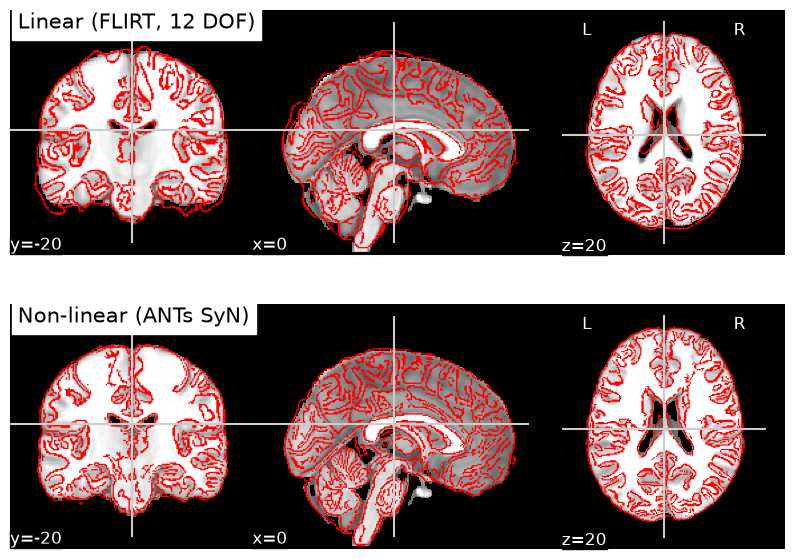

FLIRT: correlation with MNI template = 0.625
ANTs SyN: correlation with MNI template = 0.777


In [23]:
# Compare linear (FLIRT) and non-linear (ANTs SyN) registration
fig, axes = plt.subplots(2, 1, figsize=(10, 7))

for ax, (img_path, title) in zip(
    axes,
    [(registered_path, "Linear (FLIRT, 12 DOF)"),
     (ants_path, "Non-linear (ANTs SyN)")]
):
    disp = plotting.plot_anat(
        str(reference),
        title=title,
        display_mode="ortho",
        cut_coords=(0, -20, 20),
        dim=-0.3,
        axes=ax
    )
    disp.add_edges(str(img_path), color="red")

plt.show()

# Simple quantitative comparison: correlation with the template inside the template brain
ref_data = reference_img.get_fdata()
ref_mask = ref_data > 0

for name, path in [("FLIRT", registered_path), ("ANTs SyN", ants_path)]:
    data = nib.load(str(path)).get_fdata()
    r = np.corrcoef(ref_data[ref_mask], data[ref_mask])[0, 1]
    print(f"{name}: correlation with MNI template = {r:.3f}")

### 3.8.1 Registration Comparison Results

We compared the affine registration obtained with FSL FLIRT and the nonlinear registration obtained with ANTs SyN using the MNI152 template as the reference.

Both registered images were visualized in sagittal, coronal, and axial views, with their anatomical edges overlaid on the MNI template. The FLIRT registration provided reasonable global alignment, while ANTs SyN appeared to improve the correspondence of several anatomical boundaries, particularly around the cortical regions.

To complement the visual inspection, we calculated the Pearson correlation between the registered image intensities and the MNI152 template within the nonzero template mask.

The correlation was **0.625 for FLIRT** and **0.777 for ANTs SyN**, indicating greater intensity similarity with the template after nonlinear registration.

These results suggest that ANTs SyN improves the alignment for this subject compared with affine registration alone. However, intensity correlation is an indirect measure of registration quality and does not guarantee anatomically accurate correspondence in every region.

Since the HCP functional data are provided in MNI space after nonlinear registration, we use the SyN-registered T1 (`T1w_brain_MNI_SyN.nii.gz`) as the anatomical reference for the functional overlay in the next notebook.

### 3.9 Bringing the Tissue Maps to MNI Space

The FAST partial-volume maps are still in the subject's native space. To use them together with the functional data (e.g., white-matter or CSF masks), we apply the FLIRT transformation estimated above to each map.

CSF map in MNI space: T1w_fast_CSF_MNI.nii.gz
GM map in MNI space: T1w_fast_GM_MNI.nii.gz
WM map in MNI space: T1w_fast_WM_MNI.nii.gz


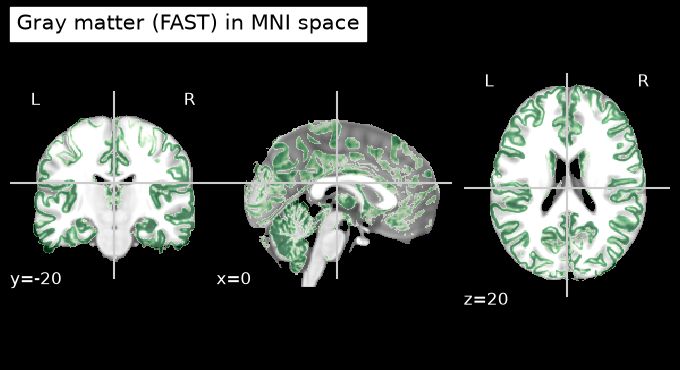

In [27]:
pve_mni_paths = {}

for tissue, path in [("CSF", csf_path), ("GM", gm_path), ("WM", wm_path)]:
    out_path = REGISTRATION_DIR / f"T1w_fast_{tissue}_MNI.nii.gz"
    subprocess.run([
        "flirt",
        "-in", str(path),
        "-ref", str(reference),
        "-applyxfm",
        "-init", str(matrix_path),
        "-interp", "trilinear",
        "-out", str(out_path)
    ], check=True)
    pve_mni_paths[tissue] = out_path
    print(f"{tissue} map in MNI space: {out_path.name}")

# Quick visual check: GM map in MNI space over the template
display = plotting.plot_anat(
    str(reference),
    title="Gray matter (FAST) in MNI space",
    display_mode="ortho",
    cut_coords=(0, -20, 20),
    dim=-0.3
)
display.add_overlay(str(pve_mni_paths["GM"]), cmap="Greens", threshold=0.5, alpha=0.6)
plotting.show()

### 3.9.1 Tissue Maps in MNI Space — Results

The FAST partial-volume maps for CSF, gray matter, and white matter were transformed from the subject's native anatomical space to MNI152 space using the affine transformation estimated by FLIRT.

Trilinear interpolation was used to resample the tissue maps onto the MNI152 1 mm reference grid, preserving their interpretation as continuous partial-volume estimates rather than discrete tissue labels.

Visual inspection showed anatomically reasonable tissue distributions. CSF remained concentrated around the ventricles and cortical sulci, gray matter followed the cortical ribbon and deeper gray-matter structures, and white matter was primarily located in the internal brain regions.

The transformed tissue maps can be used for subsequent analyses requiring anatomical information in MNI space. However, their alignment with functional data must be verified separately, and any masks derived from these maps should be checked after thresholding.

In [28]:
# Verify the FAST tissue maps transformed into MNI space
print("MNI-space tissue maps — Quality Control")
print("-" * 50)

for tissue, path in pve_mni_paths.items():
    img = nib.load(str(path))
    data = img.get_fdata(dtype=np.float32)

    # Verify MNI reference geometry
    assert img.shape == reference_img.shape, f"{tissue}: incorrect dimensions"
    assert np.allclose(img.affine, reference_img.affine), f"{tissue}: incorrect affine"

    # Verify partial-volume values
    assert np.all(np.isfinite(data)), f"{tissue}: invalid values"
    assert data.min() >= -1e-4, f"{tissue}: values below 0"
    assert data.max() <= 1.0001, f"{tissue}: values above 1"

    print(f"\n{tissue}:")
    print(f"  Dimensions: {img.shape}")
    print(f"  Voxel size: {img.header.get_zooms()[:3]}")
    print(f"  PVE range: {data.min():.3f} - {data.max():.3f}")
    print("  Status: OK")

print("\nAll MNI-space tissue maps passed quality checks.")

MNI-space tissue maps — Quality Control
--------------------------------------------------

CSF:
  Dimensions: (182, 218, 182)
  Voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  PVE range: 0.000 - 1.000
  Status: OK

GM:
  Dimensions: (182, 218, 182)
  Voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  PVE range: 0.000 - 1.000
  Status: OK

WM:
  Dimensions: (182, 218, 182)
  Voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  PVE range: 0.000 - 1.000
  Status: OK

All MNI-space tissue maps passed quality checks.


## 4. Structural Preprocessing Summary

In this notebook, we completed the structural preprocessing of the HCP T1-weighted anatomical MRI using the methods introduced in the NX-421 laboratory sessions.

The preprocessing pipeline included:

1. **Skull stripping (BET):** Removed non-brain tissues from the original T1-weighted MRI and generated a binary brain mask.
2. **Tissue segmentation (FAST):** Estimated the partial-volume fractions of cerebrospinal fluid (CSF), gray matter (GM), and white matter (WM).
3. **Affine registration (FLIRT):** Aligned the skull-stripped anatomical image to the MNI152 1 mm template using a 12-degree-of-freedom transformation.
4. **Nonlinear registration (ANTs SyN):** Performed an additional nonlinear registration to improve anatomical correspondence with the MNI template.
5. **Tissue map transformation:** Applied the FLIRT affine transformation to the FAST tissue maps to bring them into MNI space.

The results were evaluated using Matplotlib, Nilearn, and FSLeyes, together with quantitative and geometric quality checks.

Both FLIRT and ANTs SyN produced anatomically reasonable registration results in the inspected slices. ANTs SyN showed greater intensity correlation with the MNI template (0.777) than FLIRT (0.625), suggesting improved image similarity after nonlinear registration.

The transformed CSF, GM, and WM maps matched the MNI152 reference geometry and contained valid partial-volume values between 0 and 1.

Overall, the structural preprocessing pipeline produced brain-extracted anatomical images, tissue probability maps, registered anatomical images, and spatial transformations that can support subsequent functional preprocessing and statistical analyses.

The registered anatomical images and tissue maps are available in MNI space. However, alignment with functional MRI data must still be established and verified separately.

In [29]:
# Final structural preprocessing output checks
outputs = {
    "Skull-stripped T1w": brain_path,
    "Brain mask": mask_path,
    "CSF partial-volume map": csf_path,
    "Gray matter partial-volume map": gm_path,
    "White matter partial-volume map": wm_path,
    "MNI-registered T1w": registered_path,
    "FLIRT affine matrix": matrix_path,
    "MNI-registered T1w (ANTs SyN)": ants_path,
    "ANTs SyN deformation field": ants_warp_path,
    "ANTs SyN affine transformation": ants_affine_path,
    **{f"{t} map in MNI space": p for t, p in pve_mni_paths.items()}
}


print("Structural Preprocessing — Final Outputs")
print("-" * 60)

for name, path in outputs.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing output: {path}")

    print(f"[OK] {name}")
    print(f"     {path.relative_to(PROJECT_ROOT)}")

# Check that registration output matches the MNI reference grid
registered_img = nib.load(str(registered_path))
reference_img = nib.load(str(reference))

assert registered_img.shape == reference_img.shape
assert np.allclose(registered_img.affine, reference_img.affine)

# Check transformation matrix
affine_matrix = np.loadtxt(matrix_path)

assert affine_matrix.shape == (4, 4)
assert np.all(np.isfinite(affine_matrix))
assert np.allclose(affine_matrix[3], [0, 0, 0, 1])

print("\nAll structural preprocessing outputs verified.")

Structural Preprocessing — Final Outputs
------------------------------------------------------------
[OK] Skull-stripped T1w
     outputs/structural/T1w_brain.nii.gz
[OK] Brain mask
     outputs/structural/T1w_brain_mask.nii.gz
[OK] CSF partial-volume map
     outputs/structural/T1w_fast_pve_0.nii.gz
[OK] Gray matter partial-volume map
     outputs/structural/T1w_fast_pve_1.nii.gz
[OK] White matter partial-volume map
     outputs/structural/T1w_fast_pve_2.nii.gz
[OK] MNI-registered T1w
     outputs/registration_mni/T1w_brain_MNI.nii.gz
[OK] FLIRT affine matrix
     outputs/registration_mni/T1w_to_MNI_affine.mat
[OK] MNI-registered T1w (ANTs SyN)
     outputs/registration_mni/T1w_brain_MNI_SyN.nii.gz
[OK] ANTs SyN deformation field
     outputs/registration_mni/T1w_to_MNI_SyN_Warp.nii.gz
[OK] ANTs SyN affine transformation
     outputs/registration_mni/T1w_to_MNI_SyN_Affine.mat
[OK] CSF map in MNI space
     outputs/registration_mni/T1w_fast_CSF_MNI.nii.gz
[OK] GM map in MNI space
    

Checking files...
Original T1 : FOUND -> /data/Desktop/myfiles/NX421-MiniProject-1/data/T1/T1w.nii.gz
BET         : FOUND -> /data/Desktop/myfiles/NX421-MiniProject-1/outputs/structural/T1w_brain.nii.gz
Mask        : FOUND -> /data/Desktop/myfiles/NX421-MiniProject-1/outputs/structural/T1w_brain_mask.nii.gz
CSF         : FOUND -> /data/Desktop/myfiles/NX421-MiniProject-1/outputs/structural/T1w_fast_pve_0.nii.gz
GM          : FOUND -> /data/Desktop/myfiles/NX421-MiniProject-1/outputs/structural/T1w_fast_pve_1.nii.gz
WM          : FOUND -> /data/Desktop/myfiles/NX421-MiniProject-1/outputs/structural/T1w_fast_pve_2.nii.gz
FLIRT       : FOUND -> /data/Desktop/myfiles/NX421-MiniProject-1/outputs/registration_mni/T1w_brain_MNI.nii.gz
SyN         : FOUND -> /data/Desktop/myfiles/NX421-MiniProject-1/outputs/registration_mni/T1w_brain_MNI_SyN.nii.gz
MNI         : FOUND -> /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18/data/standard/MNI1

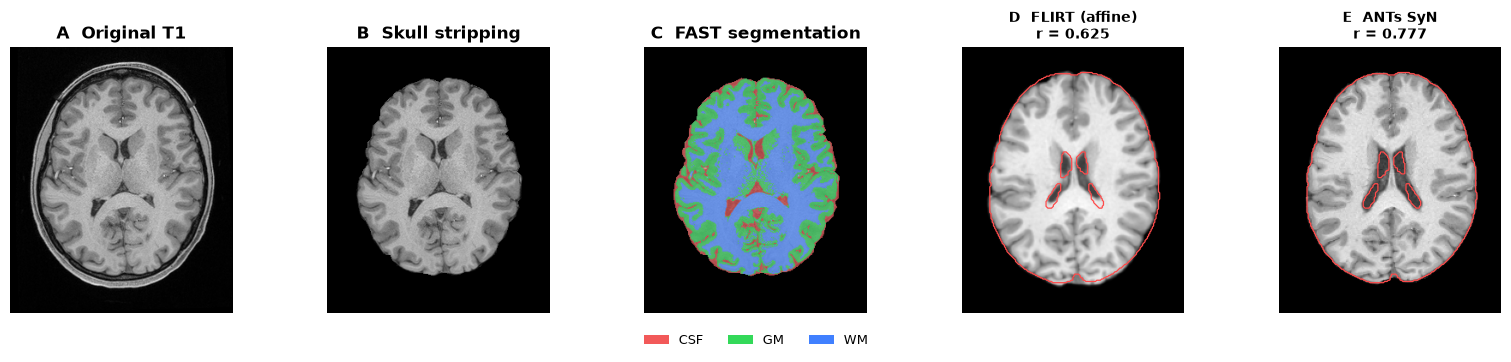

Figure saved: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/report_figures/structural_pipeline_summary.png


In [12]:
# ============================================================
# REPORT FIGURE 1 — STRUCTURAL PREPROCESSING PIPELINE
# Add this cell at the END of notebook 01
# ============================================================

from pathlib import Path
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import os

ROOT = Path("/data/Desktop/myfiles/NX421-MiniProject-1")
STRUCT = ROOT / "outputs" / "structural"
REG = ROOT / "outputs" / "registration_mni"
FIG_DIR = ROOT / "outputs" / "report_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

mni_path = (
    Path(os.environ["FSLDIR"])
    / "data/standard/MNI152_T1_1mm_brain.nii.gz"
)

files = {
    "Original T1": ROOT / "data" / "T1" / "T1w.nii.gz",
    "BET": STRUCT / "T1w_brain.nii.gz",
    "Mask": STRUCT / "T1w_brain_mask.nii.gz",
    "CSF": STRUCT / "T1w_fast_pve_0.nii.gz",
    "GM": STRUCT / "T1w_fast_pve_1.nii.gz",
    "WM": STRUCT / "T1w_fast_pve_2.nii.gz",
    "FLIRT": REG / "T1w_brain_MNI.nii.gz",
    "SyN": REG / "T1w_brain_MNI_SyN.nii.gz",
    "MNI": mni_path,
}

print("Checking files...")
for name, path in files.items():
    print(f"{name:12s}: {'FOUND' if path.exists() else 'MISSING'} -> {path}")

missing = [name for name, path in files.items() if not path.exists()]
if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

def load_canonical(path):
    img = nib.as_closest_canonical(nib.load(str(path)))
    return img, img.get_fdata(dtype=np.float32)

images = {name: load_canonical(path) for name, path in files.items()}

def axial(data, z):
    return np.rot90(data[:, :, z])

# Native-space slice for original / BET / FAST
mask = images["Mask"][1]
brain_voxels = np.argwhere(mask > 0)
z_native = int(np.rint(brain_voxels[:, 2].mean()))

# MNI-space slice for FLIRT / SyN
mni_img, mni_data = images["MNI"]
z_mni = int(np.rint(
    nib.affines.apply_affine(
        np.linalg.inv(mni_img.affine),
        [0, 0, 20]
    )[2]
))

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
fig.patch.set_facecolor("white")

# A — Original T1
axes[0].imshow(axial(images["Original T1"][1], z_native), cmap="gray")
axes[0].set_title("A  Original T1", fontweight="bold")

# B — BET skull stripping
axes[1].imshow(axial(images["BET"][1], z_native), cmap="gray")
axes[1].set_title("B  Skull stripping", fontweight="bold")

# C — FAST segmentation
background = axial(images["BET"][1], z_native)
axes[2].imshow(background, cmap="gray")

tissue = np.stack([
    axial(images["CSF"][1], z_native),
    axial(images["GM"][1], z_native),
    axial(images["WM"][1], z_native)
], axis=-1)

dominant = np.argmax(tissue, axis=-1)
strength = np.max(tissue, axis=-1)

palette = np.array([
    [0.95, 0.35, 0.35],  # CSF
    [0.20, 0.85, 0.35],  # GM
    [0.25, 0.50, 1.00],  # WM
])

rgba = np.zeros((*dominant.shape, 4))
rgba[..., :3] = palette[dominant]
rgba[..., 3] = np.where(strength > 0.40, 0.65, 0.0)

axes[2].imshow(rgba)
axes[2].set_title("C  FAST segmentation", fontweight="bold")

# D and E — Registration to MNI
for ax, key, title, corr in [
    (axes[3], "FLIRT", "D  FLIRT (affine)", 0.625),
    (axes[4], "SyN", "E  ANTs SyN", 0.777),
]:
    registered = images[key][1]

    if registered.shape != mni_data.shape:
        raise ValueError(
            f"{key} and MNI grids differ"
        )

    reg_slice = axial(registered, z_mni)
    ref_slice = axial(mni_data, z_mni)

    # Display the REGISTERED anatomical image
    ax.imshow(reg_slice, cmap="gray")

    # Overlay the MNI template boundary
    ax.contour(
        ref_slice > 0.15 * np.max(ref_slice),
        levels=[0.5],
        colors=["#FF4B4B"],
        linewidths=0.9
    )

    ax.set_title(
        f"{title}\nr = {corr:.3f}",
        fontweight="bold",
        fontsize=10
    )

for ax in axes:
    ax.axis("off")

fig.legend(
    handles=[
        Patch(facecolor="#F25959", label="CSF"),
        Patch(facecolor="#33D959", label="GM"),
        Patch(facecolor="#4080FF", label="WM"),
    ],
    loc="lower center",
    ncol=3,
    frameon=False,
    fontsize=9,
    bbox_to_anchor=(0.5, 0.005)
)

fig.subplots_adjust(
    left=0.01, right=0.99,
    top=0.87, bottom=0.13,
    wspace=0.06
)

save_path = FIG_DIR / "structural_pipeline_summary.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", save_path)